# Tome 11, Appendix B: Zeta and random matrices (Python companion)

Exercises first, solutions at the end. We sample large random matrices and watch the semicircle appear, test the Wigner surmises on $2\times2$ and on large matrices, compute $1000$ zeros of $\zeta$ and compare their spacings and pair correlation with the GUE, check the mean square theorem to the right of the critical line, and estimate the moments of $|\det(1-U)|$ for random unitary matrices. We use `numpy`, `mpmath` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
rng = np.random.default_rng(2026)
sc = lambda x: np.sqrt(np.maximum(4 - x * x, 0)) / (2 * np.pi)

## Exercises

**P5.1 (★) The semicircle.** Sample a $2000\times2000$ symmetric matrix with Gaussian entries and one with random signs $\pm1$. Plot the histograms of the eigenvalues of $X/\sqrt n$ against the semicircle, and compare the empirical moments $m_n(2k)$ with the Catalan numbers (Theorem 5.3).

**P5.2 (★★) Spacings of random matrices.** Check Proposition 5.4 on $10^6$ random $2\times2$ matrices. Then take $200$ GUE matrices of size $400$, unfold the eigenvalues in the bulk with the semicircle density, and compare the spacings with the surmise.

**P5.3 (★★) Zeros of zeta.** Compute the first $1000$ zeros, unfold them (Exercise 5.10), and compare the spacing histogram with the GUE surmise and with $e^{-s}$. What fraction of spacings is below $0.2$?

**P5.4 (★★) Pair correlation.** With the same zeros, compute the histogram of all differences $\tilde\gamma_j-\tilde\gamma_k$ in $]0,3]$ and compare with Montgomery's $1-\bigl(\frac{\sin\pi u}{\pi u}\bigr)^2$.

**P5.5 (★) Mean square.** Compute $\frac1T\int_T^{2T}|\zeta(\sigma+it)|^2\,dt$ for $\sigma=0.75$ and $T=100,1000$, and compare with $\zeta(1.5)$ (Theorem 5.7). Do the same on the critical line, against $\log T$.

**P5.6 (★★) Random unitary matrices.** Sample Haar unitary matrices of size $N=10$ and estimate $\mathbb E|\det(1-U)|^{2k}$ for $k=1,2$. Compare with the product formula of Remark 5.4.

## Solutions

### P5.1
**How to find it.** `np.linalg.eigvalsh` diagonalises a $2000\times2000$ symmetric matrix in a second or two.

Gaussian  extreme eigenvalues -1.9837 2.0000  moments m(2k), k=1..4: [1.001, 2.003, 5.011, 14.041]  Catalan: 1, 2, 5, 14


random signs  extreme eigenvalues -1.9945 1.9803  moments m(2k), k=1..4: [1.0, 2.0, 4.999, 13.992]  Catalan: 1, 2, 5, 14


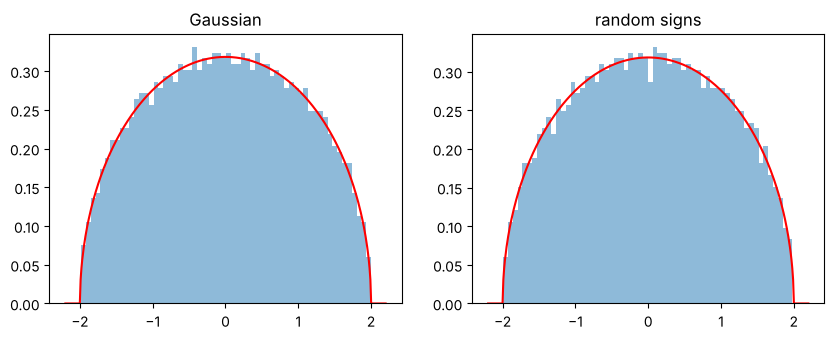

In [2]:
n = 2000
A = rng.standard_normal((n, n)); Xg = (A + A.T) / np.sqrt(2)
B = rng.choice([-1.0, 1.0], size=(n, n)); Xs = np.triu(B) + np.triu(B, 1).T
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = np.linspace(-2.2, 2.2, 400)
for ax, X, name in ((axes[0], Xg, 'Gaussian'), (axes[1], Xs, 'random signs')):
    lam = np.linalg.eigvalsh(X) / np.sqrt(n)
    ax.hist(lam, bins=60, density=True, alpha=0.5); ax.plot(x, sc(x), 'r'); ax.set_title(name)
    print(name, ' extreme eigenvalues %.4f %.4f' % (lam.min(), lam.max()),
          ' moments m(2k), k=1..4:', [round(float(np.mean(lam ** (2 * k))), 3) for k in range(1, 5)], ' Catalan: 1, 2, 5, 14')
plt.show()

Both matrices give the semicircle, with the extreme eigenvalues within a few hundredths of $\pm2$: universality in action. The moments are close to $1,2,5,14$; the Gaussian ones are slightly larger, by about $\frac5n$ for $m(4)$, as Exercise 5.2 predicts.

### P5.2
**How to find it.** For the large matrices, map each eigenvalue $\lambda$ (scaled by $\sqrt n$) to $nF(\lambda)$, where $F$ is the semicircle distribution function; the unfolded eigenvalues have mean spacing $1$. Keep the middle half of the spectrum, where the density is nearly flat.

P(s < 0.1): GOE 2x2 0.00782 (surmise 0.00782), GUE 2x2 0.001077 (surmise 0.001081)


GUE N=400 bulk: 39775 spacings, mean 0.9995, P(s<0.2) = 0.0085, surmise 0.0086


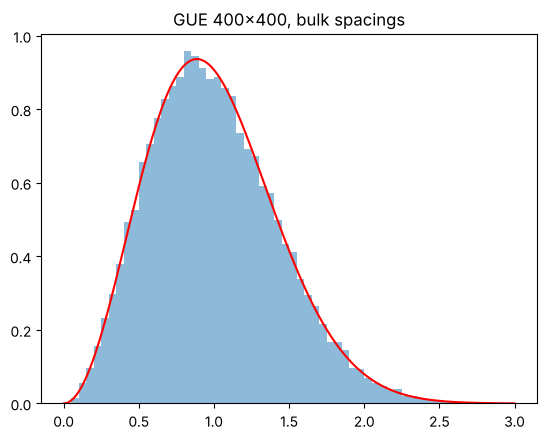

In [3]:
M = 10**6
a, c = rng.standard_normal(M), rng.standard_normal(M)
b = rng.normal(0, np.sqrt(0.5), M); u, v = rng.normal(0, np.sqrt(0.5), (2, M))
D1 = np.sqrt((a - c) ** 2 + 4 * b ** 2); D2 = np.sqrt((a - c) ** 2 + 4 * (u * u + v * v))
s1, s2 = D1 / D1.mean(), D2 / D2.mean()
p1 = lambda s: np.pi / 2 * s * np.exp(-np.pi * s * s / 4)
p2 = lambda s: 32 / np.pi ** 2 * s * s * np.exp(-4 * s * s / np.pi)
print('P(s < 0.1): GOE 2x2 %.5f (surmise %.5f), GUE 2x2 %.6f (surmise %.6f)' % (np.mean(s1 < 0.1), 1 - np.exp(-np.pi * 0.01 / 4), np.mean(s2 < 0.1), 32 / (3 * np.pi ** 2) * 1e-3))
F = lambda x: 0.5 + (x * np.sqrt(4 - x * x) / 2 + 2 * np.arcsin(x / 2)) / (2 * np.pi)
sp = []
N = 400
for _ in range(200):
    Z = (rng.standard_normal((N, N)) + 1j * rng.standard_normal((N, N))) / np.sqrt(2)
    H = (Z + Z.conj().T) / np.sqrt(2)
    lam = np.linalg.eigvalsh(H) / np.sqrt(N)
    t = N * F(np.clip(lam, -2, 2))
    t = t[(t > N / 4) & (t < 3 * N / 4)]
    sp.extend(np.diff(t))
sp = np.array(sp)
print('GUE N=400 bulk: %d spacings, mean %.4f, P(s<0.2) = %.4f, surmise %.4f' % (len(sp), sp.mean(), np.mean(sp < 0.2), 32 / (3 * np.pi ** 2) * 0.008))
xs = np.linspace(0, 3, 200)
plt.hist(sp, bins=60, range=(0, 3), density=True, alpha=0.5); plt.plot(xs, p2(xs), 'r'); plt.title('GUE 400x400, bulk spacings'); plt.show()

For $2\times2$ matrices the surmises are exact, and the simulation agrees to Monte Carlo accuracy. For large GUE matrices the spacing law is Gaudin's, which differs from the $2\times2$ surmise by at most about $0.01$ in density: the histogram sits on the red curve. Small spacings are rare: the cubic vanishing at $0$ is level repulsion.

### P5.3
**How to find it.** Sign changes of $Z$ between consecutive Gram points find most zeros but not all: where Gram's law fails, a Gram interval can hold two zeros
and no sign change at its ends, and a coarse search skips both. `mpmath.zetazero(k)` locates the $k$-th zero using Gram blocks and Rosser's rule, so no zero
is skipped; we check the count against the Riemann--von Mangoldt formula with `mpmath.nzeros`. About three minutes.

1000 zeros up to 1419.422 in 225 s; mpmath nzeros: 1000
mean spacing 1.0000, P(s < 0.2) = 0.0030 (GUE surmise 0.0086, Poisson 0.1813)


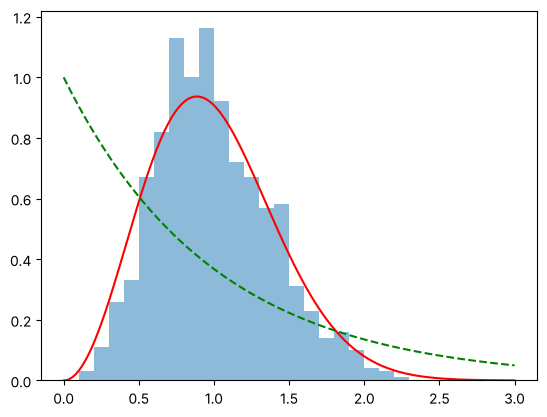

In [4]:
mp.mp.dps = 15
t0 = time.time()
gam = np.array([float(mp.zetazero(k).imag) for k in range(1, 1001)])
print('1000 zeros up to %.3f in %.0f s; mpmath nzeros: %d' % (gam[-1], time.time() - t0, mp.nzeros(gam[-1] + 1e-6)))
unf = gam / (2 * np.pi) * np.log(gam / (2 * np.pi * np.e)) + 7 / 8
s = np.diff(unf)
print('mean spacing %.4f, P(s < 0.2) = %.4f (GUE surmise %.4f, Poisson %.4f)' % (s.mean(), np.mean(s < 0.2), 32 / (3 * np.pi ** 2) * 0.008, 1 - np.exp(-0.2)))
plt.hist(s, bins=30, range=(0, 3), density=True, alpha=0.5); plt.plot(xs, p2(xs), 'r'); plt.plot(xs, np.exp(-xs), 'g--'); plt.show()

The unfolded spacings have mean $1$ and almost no small values: under one percent are below $0.2$, while independent points would give $18\%$. The surmise integral is computed to leading order, $\frac{32}{3\pi^2}(0.2)^3\approx0.0086$; the exact value is a little smaller. The fit is already good at this low height, and Odlyzko's zeros near $10^{20}$ fit even better.

### P5.4
**How to find it.** For each zero, collect the differences to the following zeros up to distance $3$; normalise the histogram by the number of zeros.

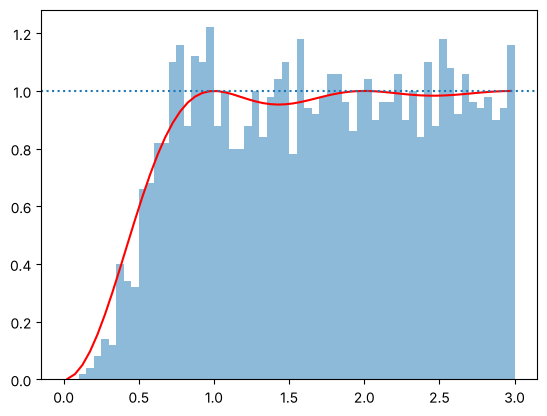

mean |density - Montgomery| over (0,3]: 0.089


In [5]:
diffs = []
for j in range(len(unf)):
    k = j + 1
    while k < len(unf) and unf[k] - unf[j] <= 3:
        diffs.append(unf[k] - unf[j]); k += 1
h, edges = np.histogram(diffs, bins=60, range=(0, 3))
mid = (edges[:-1] + edges[1:]) / 2
dens = h / (len(unf) * (edges[1] - edges[0]))
mont = 1 - (np.sin(np.pi * mid) / (np.pi * mid)) ** 2
plt.bar(mid, dens, width=0.05, alpha=0.5); plt.plot(mid, mont, 'r'); plt.axhline(1, ls=':'); plt.show()
print('mean |density - Montgomery| over (0,3]: %.3f' % np.mean(np.abs(dens - mont)))

The pair correlation of the zeros follows $1-(\frac{\sin\pi u}{\pi u})^2$: a hole near $0$, then oscillations that settle at $1$. With $1000$ zeros the histogram is noisy (each bin has a few hundred pairs), but the shape is unmistakable.

### P5.5
**How to find it.** `mp.zeta` evaluates $\zeta(\sigma+it)$; a trapezoidal rule with step $0.05$ is accurate enough, since $\zeta$ oscillates on the scale $\frac{2\pi}{\log t}$.

In [6]:
mp.mp.dps = 12
for sigma in (0.75, 0.5):
    for T in (100, 1000):
        ts = np.arange(T, 2 * T + 1e-9, 0.05)
        vals = np.array([abs(complex(mp.zeta(mp.mpc(sigma, t)))) ** 2 for t in ts])
        mean = np.trapezoid(vals, ts) / T
        ref = float(mp.zeta(2 * sigma)) if sigma > 0.5 else math.log(T)
        print('sigma=%.2f  T=%5d  mean |zeta|^2 = %.4f   %s = %.4f' % (sigma, T, mean, 'zeta(2 sigma)' if sigma > 0.5 else 'log T', ref))

sigma=0.75  T=  100  mean |zeta|^2 = 2.3543   zeta(2 sigma) = 2.6124


sigma=0.75  T= 1000  mean |zeta|^2 = 2.5178   zeta(2 sigma) = 2.6124


sigma=0.50  T=  100  mean |zeta|^2 = 4.4119   log T = 4.6052


sigma=0.50  T= 1000  mean |zeta|^2 = 6.6176   log T = 6.9078


At $\sigma=0.75$ the averages are close to $\zeta(1.5)=2.612$, with a slowly decreasing error (of order $T^{-1/2}$ here). On the critical line the mean grows like $\log T$, as Hardy and Littlewood proved: more precisely $\frac1T\int_T^{2T}|\zeta(\frac12+it)|^2\,dt=\log T+O(1)$, and the full asymptotic $\int_0^T|\zeta(\frac12+it)|^2\,dt=T\log\frac T{2\pi}+(2\gamma-1)T+o(T)$ (Ingham) makes that $O(1)$ tend to $2\gamma-1-\log 2\pi+\log 4\approx-0.30$. Compare with the last column of the output.

### P5.6
**How to find it.** A Haar unitary: take the QR decomposition of a complex Gaussian matrix and fix the phases of the diagonal of $R$ (Mezzadri's recipe).

In [7]:
def haar(N):
    Z = (rng.standard_normal((N, N)) + 1j * rng.standard_normal((N, N))) / np.sqrt(2)
    Q, Rm = np.linalg.qr(Z)
    d = np.diag(Rm); return Q * (d / np.abs(d))
N, M = 10, 200000
vals = np.empty(M)
for i in range(M):
    vals[i] = abs(np.linalg.det(np.eye(N) - haar(N))) ** 2
for k in (1, 2):
    exact = math.prod(math.gamma(j) * math.gamma(j + 2 * k) / math.gamma(j + k) ** 2 for j in range(1, N + 1))
    est = np.mean(vals ** k); err = np.std(vals ** k) / math.sqrt(M)
    print('k=%d  Monte Carlo %.3f +- %.3f   exact %.3f' % (k, est, 2 * err, exact))

k=1  Monte Carlo 10.992 +- 0.179   exact 11.000
k=2  Monte Carlo 1722.800 +- 197.798   exact 1716.000


For $k=1$ the exact value is $N+1=11$, and for $k=2$ it is $\frac{(N+1)(N+2)^2(N+3)}{12}=1716$. The Monte Carlo estimates agree within their error bars (the $k=2$ estimate is noisier, because $|\det|^4$ has heavy tails). These are the numbers that, with $N$ replaced by $\log\frac T{2\pi}$, give the Hardy–Littlewood and Ingham moments.